# Module 2: Data pitfalls

Most "too good to be true" backtests are data bugs. This notebook demonstrates the main ones
on simulated data first, where the truth is known, and then finds them in our own data:

1. Universes and point-in-time S&P 500 membership
2. Survivorship bias
3. Look-ahead bias
4. Trading calendars, missing data and stale prices
5. Sanity checks: what a 50% daily move usually means
6. Exercises

Lecture notes, glossary and interview questions: [`lecture.md`](lecture.md).
New code: `statarb.universe`, `statarb.checks`, and `data.clean_prices`,
`data.sanity_report`, `data.flag_returns`.

In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from statarb import checks, data, returns, universe
from statarb.config import TRADING_DAYS

logging.getLogger("yfinance").setLevel(logging.CRITICAL)  # delisted tickers are expected
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

START, END = "2016-01-01", "2025-12-31"  # ten years

## 1. Universes and point-in-time S&P 500 membership

A **universe** is the set of assets a strategy is allowed to trade. Choosing it is the
first place bias creeps in: "the S&P 500" today is not the S&P 500 of 2016.

We rebuild historical membership from two Wikipedia pages, pinned to fixed revisions so the
result is reproducible: today's constituent list and the table of historical changes.

In [2]:
current, changes = universe.load_sp500_tables()
print(f"current members: {len(current)}   recorded changes: {len(changes)}")
print(f"changes table covers {changes['date'].min().date()} to {changes['date'].max().date()}")
changes.head(8)

current members: 503   recorded changes: 415
changes table covers 1976-07-01 to 2026-10-30


,date,added,removed,reason
0,2026-10-30,OKTA,KVUE,S&P 500 constituent Kimberly-Clark acquired Ke...
1,2026-10-06,TWLO,WBD,Paramount Skydance acquired Warner Bros. Disco...
2,2026-10-06,NaN,CTVA,Market capitalization changes.
3,2026-10-01,VYLR,NaN,Corteva completed the corporate spin-off of Vylor
4,2026-09-21,BE,TAP,Market capitalization changes.
5,2026-09-21,P,TTD,Market capitalization changes.
6,2026-09-21,ILMN,BLDR,Market capitalization changes.
7,2026-08-18,RDDT,AVB,Equity Residential (now Vivmark Residential) a...


Each change row adds a ticker, removes one, or both. To get the members on a past date,
`universe.members_asof` starts from today's list and *undoes* every later change (drop what
was added, restore what was removed).

The index has about 500 companies (503 tickers today, since some companies have two share
classes). If the changes table were complete, the reconstructed count would stay near 503
all the way back. It doesn't:

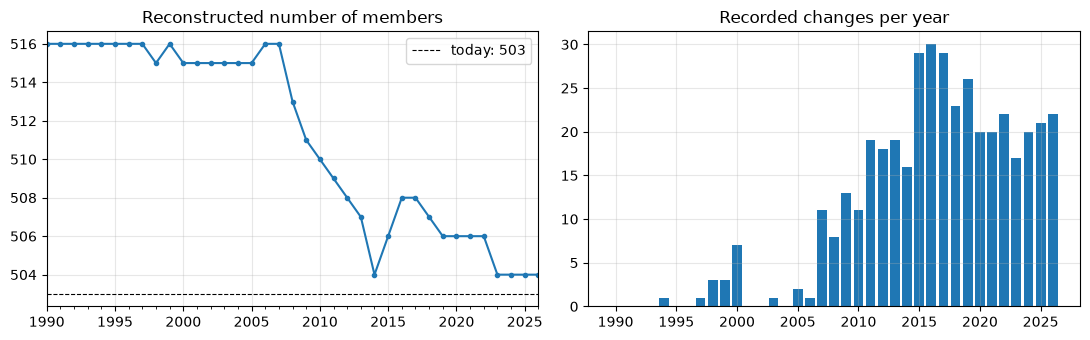

In [3]:
years = pd.date_range("1990-01-01", "2026-01-01", freq="YS")
counts = pd.Series(
    [len(universe.sp500_members_asof(d, current, changes)) for d in years], index=years
)
per_year = changes.groupby(changes["date"].dt.year).size().reindex(range(1990, 2027), fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
counts.plot(ax=axes[0], marker=".")
axes[0].axhline(503, color="k", ls="--", lw=0.8, label="today: 503")
axes[0].set_title("Reconstructed number of members")
axes[0].legend()
axes[1].bar(per_year.index, per_year.to_numpy(), width=0.8)
axes[1].set_title("Recorded changes per year")
fig.tight_layout()

The count drifts upwards going back (to about 516 before 2007), and the table records only
a handful of changes a year before about 2008, when the true turnover was 20–30 names a
year. Some removals were recorded without the matching addition. The reconstruction is good for the
last decade (within about 1%) and increasingly unreliable before that. **Free data limits
how far back point-in-time work can go**; that is why professional point-in-time databases
are expensive.

How different is the index today from ten years ago?

In [4]:
today = pd.Timestamp("2026-11-12")
then = set(universe.sp500_members_asof(today - pd.DateOffset(years=10), current, changes))
now = set(current["ticker"])
print(f"members today that were not members ten years ago: {len(now - then)}")
print(f"members ten years ago that are gone today:          {len(then - now)}")


def reason_type(text: str) -> str:
    text = str(text).lower()
    if "acqui" in text or "merg" in text:
        return "acquired / merged"
    if "spin" in text:
        return "spin-off"
    if "market cap" in text:
        return "market cap change"
    return "other"


recent = changes[changes["date"] >= today - pd.DateOffset(years=10)]
recent["reason"].map(reason_type).value_counts().to_frame("changes in last 10 years")

members today that were not members ten years ago: 145
members ten years ago that are gone today:          150


,changes in last 10 years
reason,
market cap change,97
acquired / merged,88
spin-off,25
other,12


About 30% of today's index wasn't in it ten years ago. Companies leave because they are
acquired, shrink (market cap falls below the threshold) or go bankrupt; they join because
they have grown. Any study that starts from today's list silently selects the winners.

The project's three universes (defined in `statarb.universe`):

In [5]:
print("U1, ETFs and classic pairs:", universe.U1)
print("U2, LARGE_CAP_100 (first 12):", universe.LARGE_CAP_100[:12], "...")
print("U3, current S&P 500:", len(current), "tickers, optionally filtered point-in-time")

U1, ETFs and classic pairs: ['SPY', 'XLB', 'XLC', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLRE', 'XLU', 'XLV', 'XLY', 'KO', 'PEP', 'XOM', 'CVX', 'EWA', 'EWC', 'GLD', 'GDX', 'V', 'MA', 'HD', 'LOW']
U2, LARGE_CAP_100 (first 12): ['AAPL', 'MSFT', 'NVDA', 'AVGO', 'ORCL', 'CSCO', 'ADBE', 'CRM', 'ACN', 'IBM', 'INTC', 'QCOM'] ...
U3, current S&P 500: 503 tickers, optionally filtered point-in-time


## 2. Survivorship bias

### 2a. Simulation: a selection effect with a known answer

Simulate 2,000 stocks for ten years as driftless geometric random walks: each stock's
*expected* price at any future date equals today's price, so the true expected return is
zero. A stock that falls below 20% of its starting price is **delisted** (think bankruptcy)
and its price is frozen there. Then compare the average return of all stocks with the
average over the survivors, which is what a database of "stocks that exist today" contains.

In [6]:
rng = np.random.default_rng(7)
n_stocks, n_days, vol = 2000, 10 * TRADING_DAYS, 0.35
sigma = vol / np.sqrt(TRADING_DAYS)
log_paths = np.cumsum(rng.normal(-(sigma**2) / 2, sigma, (n_days, n_stocks)), axis=0)
paths = np.exp(log_paths)

below = paths < 0.2
delist_day = np.where(below.any(axis=0), below.argmax(axis=0), n_days)
for j in np.flatnonzero(delist_day < n_days):
    paths[delist_day[j] :, j] = paths[delist_day[j], j]
survived = delist_day == n_days

final = pd.Series(paths[-1])
sim = pd.DataFrame(
    {
        "stocks": [n_stocks, survived.sum()],
        "mean final value (start = 1)": [final.mean(), final[survived].mean()],
        "annualised return": [final.mean() ** 0.1 - 1, final[survived].mean() ** 0.1 - 1],
    },
    index=["all stocks", "survivors only"],
)
print(f"delisted: {1 - survived.mean():.0%} of stocks")
sim

delisted: 29% of stocks


,stocks,mean final value (start = 1),annualised return
all stocks,2000,1.0092,0.0009
survivors only,1418,1.3425,0.0299


The truth is about 0% a year. The survivors show about +3% a year, purely because the
losers were removed from the sample.

*Physics analogy:* Malmquist bias. A flux-limited survey of stars sees only those bright
enough to detect, so the average luminosity of the sample overstates the population's.
A detector that only counts particles that reach it is biased the same way.

### 2b. Real data: today's members vs point-in-time members

Now the S&P 500 over 2016–2025. Download every ticker that was a member at any month-start in
the window, plus today's members.

In [7]:
months = pd.date_range(START, END, freq="MS")
monthly = universe.membership_matrix(months, current["ticker"], changes)
tickers = sorted(set(monthly.columns) | now)

bars, failed = {}, []
for t in tickers:
    try:
        bars[t] = data.load_bars(t, START, END)
    except ValueError:
        failed.append(t)

print(f"{len(tickers)} tickers needed, {len(bars)} downloaded, {len(failed)} returned no data")
print("examples of missing tickers:", failed[:15])

724 tickers needed, 601 downloaded, 123 returned no data
examples of missing tickers: ['ABMD', 'ACE', 'ADS', 'AET', 'AGN', 'ALXN', 'ANDV', 'ANSS', 'APC', 'ARG', 'ARNC', 'ATVI', 'AVB', 'BBBY', 'BCR']


A sixth of the tickers return nothing: mostly companies that were acquired (ATVI, AET,
ALXN) or went bust (BBBY). Yahoo, like most free sources, drops delisted securities. That
gap *is* the survivorship problem in the data itself. (The three current members with no
data, FDXF, HONA and VYLR, are 2026 spin-offs with no history in our window.)

Build two equal-weight portfolios, both rebalanced daily, from the adjusted closes:

- **Today's members:** the 503 current tickers, held over the whole decade.
- **Point-in-time:** on each day, the tickers that were members at the *previous* close
  (the t+1 rule) and have data.

As a reality check, add RSP, the actual S&P 500 equal-weight ETF. It held the real
point-in-time members, including the ones that later collapsed, and charges a 0.2% fee.

,annualised (compound) return
today's members,18.1%
point-in-time,13.0%
RSP (real ETF),11.6%


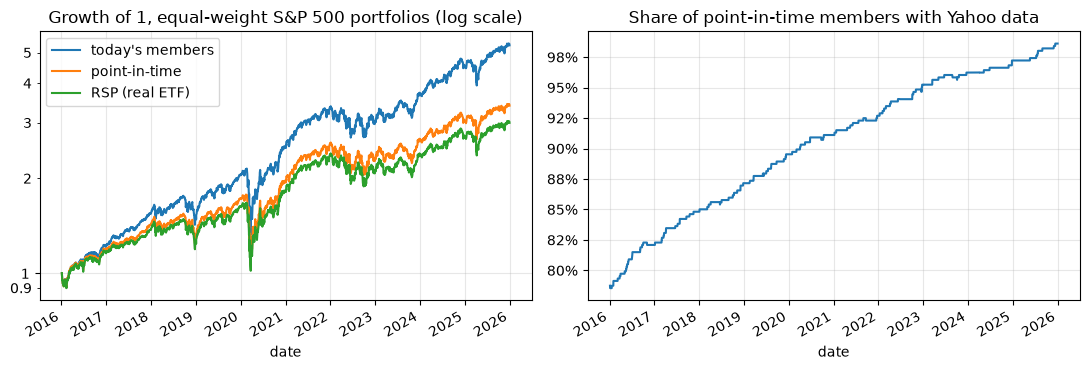

In [8]:
adj = data.clean_prices(pd.DataFrame({t: b["adj_close"] for t, b in bars.items()}))
R = returns.simple_returns(adj)

daily_members = universe.membership_matrix(adj.index, current["ticker"], changes)
held = daily_members.shift(1, fill_value=False).reindex(
    index=R.index, columns=R.columns, fill_value=False
)
rsp = returns.simple_returns(data.load_prices("RSP", START, END)["RSP"])

portfolios = pd.DataFrame(
    {
        "today's members": R[[t for t in current["ticker"] if t in R]].mean(axis=1),
        "point-in-time": R.where(held).mean(axis=1),
        "RSP (real ETF)": rsp,
    }
).dropna()

growth = (1 + portfolios).cumprod()
cagr = growth.iloc[-1] ** (TRADING_DAYS / len(growth)) - 1
coverage = (held & R.notna()).sum(axis=1) / daily_members.shift(1).sum(axis=1).loc[R.index]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
growth.plot(ax=axes[0], logy=True)
for axis in (axes[0].yaxis.set_major_formatter, axes[0].yaxis.set_minor_formatter):
    axis(plt.FuncFormatter(lambda v, _: f"{v:g}"))
axes[0].set_title("Growth of 1, equal-weight S&P 500 portfolios (log scale)")
coverage.astype(float).plot(ax=axes[1])
axes[1].set_title("Share of point-in-time members with Yahoo data")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout()
cagr.to_frame("annualised (compound) return").style.format("{:.1%}")

The ordering is the lesson:

- **Today's members** beat the real index by about 6 percentage points a year. Nobody could
  have bought this portfolio in 2016: it is chosen with knowledge of 2026.
- **Point-in-time** membership removes most of the gap, but not all. Early in the window
  only about 80% of the members have data. The missing fifth are exactly the companies that
  later disappeared, often after falling a long way.
- **RSP** is the honest number (minus a small fee and differences in rebalancing).

Survivorship bias is a form of look-ahead: the universe was chosen using information from
the future.

### 2c. Recycled tickers

Exchanges reuse tickers. Asking Yahoo for an old ticker can silently return a *different
company*. A simple check: did a ticker's price history start only after its S&P 500
membership ended?

In [9]:
report = data.sanity_report(adj)
# end of the last month in which the ticker was a member
last_member_month = monthly.iloc[::-1].idxmax() + pd.offsets.MonthEnd(1)
recycled = [
    t
    for t in monthly.columns
    if t in report.index
    and not monthly[t].iloc[-1]
    and report.loc[t, "first_date"] > last_member_month[t]
]
report.loc[recycled, ["first_date", "last_date", "max_abs_return"]].assign(
    member_until=last_member_month[recycled].dt.date
)

,first_date,last_date,max_abs_return,member_until
ticker,,,,
ADT,2018-01-19,2025-12-31,0.5656,2016-05-31
CAM,2025-10-06,2025-12-31,0.0027,2016-04-30
EMC,2023-05-15,2025-12-31,0.0820,2016-09-30
INFO,2024-10-10,2025-12-31,0.0985,2022-03-31
PCL,2025-08-05,2025-12-31,0.0106,2016-02-29
POM,2025-10-08,2025-12-31,0.9077,2016-03-31
SBNY,2024-08-15,2025-12-31,0.5595,2023-03-31
SE,2017-10-20,2025-12-31,0.3605,2017-02-28
STI,2022-05-02,2025-12-31,2.9390,2019-12-31


None of these price histories overlaps the time the ticker spent in the index: they
belong to later securities that reuse the symbol. STI was SunTrust Banks (merged into
Truist in 2019); today's STI is an unrelated small stock with daily moves of +290%. SE was
Spectra Energy; on Yahoo it is now Sea Ltd. ADT was ADT Corp, taken private in 2016; the
ADT on Yahoo is ADT Inc, which listed in 2018. Our point-in-time portfolio is
safe only because it holds a ticker *while it is a member*, and these histories start after
that. A careless "download all tickers ever in the index" study would mix them in.

## 3. Look-ahead bias

**Look-ahead bias** means a decision uses information that wasn't available when it was
made. The project rule: a signal computed with data up to day $t$ is traded at day $t+1$.

### 3a. The blatant version: trading at the price you used to decide

Rule: go long SPY after an up day and short after a down day. The signal uses day $t$'s
close. Trading it at day $t$'s close (earning day $t$'s return) is impossible; the honest
version earns day $t+1$'s return.

In [10]:
spy = returns.simple_returns(data.load_prices("SPY", START, END)["SPY"])
signal = np.sign(spy)


def sharpe(pnl: pd.Series) -> float:
    return pnl.mean() / pnl.std() * np.sqrt(TRADING_DAYS)


print(f"same-day (look-ahead): Sharpe {sharpe(signal * spy):6.2f}")
print(f"next-day (honest):     Sharpe {sharpe(signal.shift(1) * spy):6.2f}")

same-day (look-ahead): Sharpe  13.41
next-day (honest):     Sharpe  -0.35


The look-ahead version earns $|R_t|$ every day, a Sharpe ratio no real strategy has ever
had. Real bugs are rarely this obvious.

### 3b. The subtle version: normalising with the full sample

A common pattern: standardise a price series, $z_t = (x_t - \bar x)/s_x$, and bet on
reversion (short when $z_t > 0$, long when $z_t < 0$). If $\bar x$ and $s_x$ come from the
*whole sample*, $z_t$ knows where the series will spend its future.

Test it on pure random walks, which are unpredictable by construction. Both versions below
trade with the correct one-day lag; the only difference is the normalisation.

,full-sample z (leaky),expanding z (causal)
mean Sharpe,0.7654,0.0154
share > 0,0.9590,0.5090


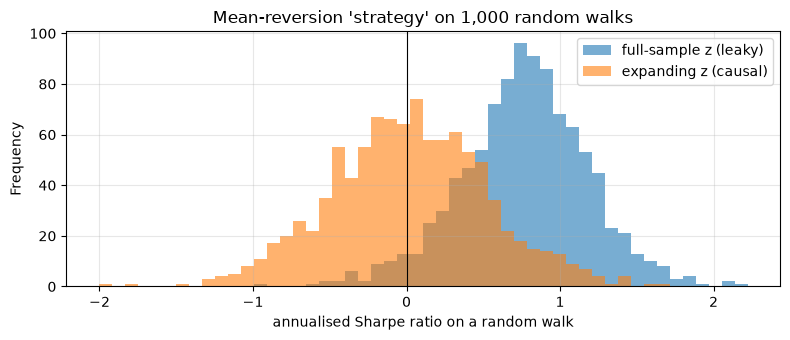

In [11]:
walks = pd.DataFrame(np.cumsum(rng.normal(0, 1, (1000, 1000)), axis=0))
next_change = walks.diff().shift(-1)  # x_{t+1} - x_t, earned by the position held at t

leaky = -(walks - walks.mean()) / walks.std()
causal = -(walks - walks.expanding(20).mean()) / walks.expanding(20).std()

sr = pd.DataFrame(
    {
        "full-sample z (leaky)": (leaky * next_change).mean() / (leaky * next_change).std(),
        "expanding z (causal)": (causal * next_change).mean() / (causal * next_change).std(),
    }
) * np.sqrt(TRADING_DAYS)

fig, ax = plt.subplots(figsize=(8, 3.5))
sr.plot.hist(bins=50, alpha=0.6, ax=ax)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("annualised Sharpe ratio on a random walk")
ax.set_title("Mean-reversion 'strategy' on 1,000 random walks")
fig.tight_layout()
sr.agg(["mean", lambda s: (s > 0).mean()]).set_axis(["mean Sharpe", "share > 0"])

The leaky version "works" on 96% of pure random walks. Nothing about the strategy is
wrong except that $\bar x$ was computed with future data. The same leak happens with
hedge ratios or thresholds fitted on the whole sample, the very thing pairs trading does.

### 3c. Catching look-ahead automatically

`checks.lookahead_violations` runs the **truncation test**: compute the signal on the full
history and on the history cut at day $t$. For a causal signal, values up to $t$ must be
identical. It is cheap, generic, and will be run on every signal in this project.

In [12]:
path = walks[0].set_axis(pd.bdate_range(START, periods=len(walks)))
for name, fn in {
    "full-sample z-score": lambda x: (x - x.mean()) / x.std(),
    "expanding z-score": lambda x: (x - x.expanding(20).mean()) / x.expanding(20).std(),
    "rolling 20-day mean": lambda x: x.rolling(20).mean(),
    "centred rolling mean": lambda x: x.rolling(21, center=True).mean(),
}.items():
    found = checks.lookahead_violations(fn, path)
    print(f"{name:22s} {'LOOK-AHEAD' if found else 'ok'}")

full-sample z-score    LOOK-AHEAD
expanding z-score      ok
rolling 20-day mean    ok
centred rolling mean   LOOK-AHEAD


A real example from writing this module: the first version of `data.clean_prices` only
forward-filled gaps *between* two prices (pandas' `limit_area="inside"`). The truncation test
failed. Deciding whether a gap is "between two prices" requires knowing a later price
exists, and on the day a price goes missing you can't know whether the stock will trade
again. The fix is a plain forward-fill with a limit.

## 4. Trading calendars, missing data and stale prices

### 4a. Different calendars

Exchanges have different holidays. Put the S&P 500 (via SPY), Japan's Nikkei 225 and the
UK's FTSE 100 on one date index:

In [13]:
world = data.load_prices(["SPY", "^N225", "^FTSE"], START, END)
print("missing values per column (raw):")
print(world.isna().sum().to_string())
world[world.isna().any(axis=1)].head(6)

missing values per column (raw):
ticker
SPY       86
^N225    156
^FTSE     75


ticker,SPY,^N225,^FTSE
date,,,
2016-01-11,161.5587,NaN,5871.7998
2016-01-18,NaN,16955.5703,5779.8999
2016-02-11,153.7797,NaN,5537.0000
2016-02-15,NaN,16022.5801,5824.2998
2016-03-21,173.0090,NaN,6184.6001
2016-03-25,NaN,17002.7500,NaN


Martin Luther King Day (third Monday in January) closes New York but not Tokyo or London;
Good Friday closes London and New York but not Tokyo. `data.clean_prices` drops dates when
nothing traded and forward-fills short gaps (at most 3 days by default):

In [14]:
world_clean = data.clean_prices(world, max_ffill=3)
print(world_clean.isna().sum().to_string())

ticker
SPY      0
^N225    3
^FTSE    0


Japan's Golden Week holidays can exceed three trading days, so a few Nikkei gaps stay
missing. That's deliberate: a long forward-fill invents a flat price, i.e. a run of fake
zero returns, which lowers measured volatility and can fake mean reversion.

### 4b. Same date is not same time

Tokyo closes about 14 hours before New York. A "daily return" dated $t$ covers different
hours in each market, so information that hits New York on day $t$ reaches Tokyo's price on
day $t+1$:

In [15]:
wr = returns.log_returns(world_clean)
lagged = pd.DataFrame(
    {
        "same date": [wr["SPY"].corr(wr[c]) for c in ("^N225", "^FTSE")],
        "SPY day t vs index day t+1": [wr["SPY"].corr(wr[c].shift(-1)) for c in ("^N225", "^FTSE")],
    },
    index=["Nikkei 225", "FTSE 100"],
)
lagged

,same date,SPY day t vs index day t+1
Nikkei 225,0.1723,0.4246
FTSE 100,0.4923,0.1490


Measured on the same date, the Nikkei looks only weakly related to the US market; with a
one-day offset the correlation more than doubles. This is **nonsynchronous trading**. It
makes "SPY today predicts the Nikkei tomorrow" look like a trading signal, but by Tokyo's
next open the information is already in the price, so you cannot trade at the stale close.
London overlaps New York for a few hours, so its same-date correlation is high.

### 4c. Stale prices

A **stale price** is one that didn't come from a trade that day. A run of identical prices
with zero volume is the signature. `sanity_report` counts both. Amcor (AMCR) joined the US
market in 2019; Yahoo shows an earlier history built from a thinly traded listing:

       first_date  n_prices  longest_flat_run  zero_volume_days
ticker                                                         
AMCR   2016-01-04      2514                66               669
KO     2016-01-04      2514                 2                 0


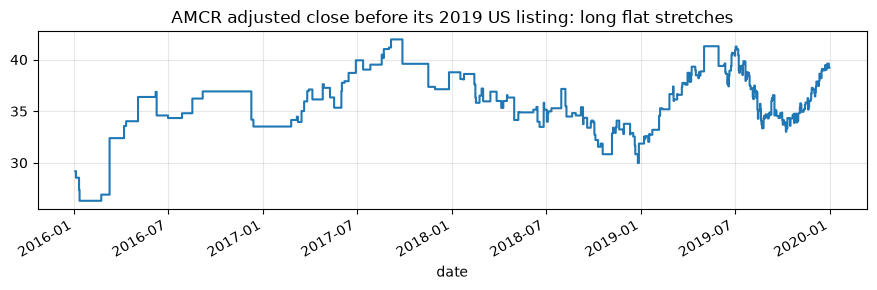

In [16]:
volume = pd.DataFrame({t: b["volume"] for t, b in bars.items()})
amcr = data.sanity_report(adj[["AMCR", "KO"]], volume=volume)
display_cols = ["first_date", "n_prices", "longest_flat_run", "zero_volume_days"]
print(amcr[display_cols].to_string())

fig, ax = plt.subplots(figsize=(9, 3))
adj.loc[:"2019-12-31", "AMCR"].plot(ax=ax, drawstyle="steps-post")
ax.set_title("AMCR adjusted close before its 2019 US listing: long flat stretches")
fig.tight_layout()

## 5. Sanity checks: what does a 50% daily move mean?

Run the report over the whole S&P 500 download and list every daily move beyond ±50%:

In [17]:
full_report = data.sanity_report(adj, volume=volume)
flags = data.flag_returns(adj, threshold=0.5)
print(
    f"tickers checked: {len(full_report)};  moves beyond 50%: {len(flags)} in {flags['ticker'].nunique()} tickers"
)
flags.head(15)

tickers checked: 601;  moves beyond 50%: 46 in 25 tickers


,date,ticker,return,prev_price,price
0,2025-10-13,STI,2.9390,5.4900,21.6250
1,2025-06-24,NKTR,1.5629,9.5400,24.4500
2,2021-01-27,GME,1.3484,36.9950,86.8775
3,2024-03-11,STI,1.2581,38.7500,87.5000
4,2025-09-03,STI,1.1372,3.2800,7.0100
5,2021-02-24,GME,1.0394,11.2425,22.9275
6,2024-08-06,LUMN,0.9305,2.5900,5.0000
7,2021-01-26,GME,0.9271,19.1975,36.9950
8,2023-08-07,NKTR,0.9245,7.9500,15.3000
9,2025-12-10,POM,-0.9077,97.5600,9.0000


Each flag needs an explanation before the data is trusted. Typical causes, all present
here:

- **Real events:** GameStop's January 2021 short squeeze (GME), PG&E's 2019 bankruptcy
  filing (PCG), and, further down the list, the oil crash of 9 March 2020 (APA, OXY, TRGP).
- **A different company under a recycled ticker:** STI (Section 2c).
- **A bad corporate-action adjustment:** DHR, below.

Danaher spun off Fortive on 1 July 2016. Yahoo recorded the spin-off as *both* a 24.56
"dividend" and a 1.319 "split" on the same day, adjusting twice:

In [18]:
bars["DHR"].loc["2016-06-29":"2016-07-07", ["close", "adj_close", "dividends", "splits"]]

,close,adj_close,dividends,splits
date,,,,
2016-06-29,67.2858,41.0296,0.00,0.000
2016-06-30,67.8840,41.3944,0.00,0.000
2016-07-01,68.7712,41.9354,0.00,0.000
2016-07-05,71.2766,67.6075,24.56,1.319
2016-07-06,71.4716,67.7925,0.00,0.000
2016-07-07,71.5426,67.8598,0.00,0.000


In [19]:
print(
    f"DHR return on 2016-07-05 from close:     {bars['DHR']['close'].pct_change()['2016-07-05']:+.1%}"
)
print(
    f"DHR return on 2016-07-05 from adj_close: {bars['DHR']['adj_close'].pct_change()['2016-07-05']:+.1%}"
)

DHR return on 2016-07-05 from close:     +3.6%
DHR return on 2016-07-05 from adj_close: +61.2%


The raw close rose 3.6% that day; the adjusted close shows +61%. Every DHR price before
July 2016 in `adj_close` is wrong by a factor of about 1.5, and any backtest holding DHR
through that date books a fake 61% gain. Spin-offs, mergers paid in shares, and special
dividends are where vendor adjustments most often break.

**Yahoo quirks to remember** (also in the lecture notes): history is revised without
notice; delisted tickers vanish; tickers are recycled; spin-offs are often mis-adjusted;
pre-listing histories can be stale; occasional bad ticks. Hence: cache with a download date,
run `sanity_report` and `flag_returns` on every new universe, and explain every flag.

## 6. Exercises

1. **No-look-ahead test.** Read `statarb/checks.py` and `tests/test_checks.py`. Write a
   signal with a subtle leak of your own (for example, a z-score using a rolling window
   with `center=True`, or prices cleaned with `bfill`) and confirm the truncation test
   catches it. Explain in one paragraph why "shifting or changing future data must not change
   past signals" is equivalent to the truncation test.
2. **A ticker change and a delisting.** Find one ticker change (e.g. FB to META) and one
   delisting in U2's history. For each, describe exactly how it would corrupt a naive
   backtest.
3. **Short histories.** Quantify the missing data for XLRE and XLC (launched 2015 and
   2018). Decide, and write down, how the project handles assets with short histories.

In [20]:
# Exercise 1

In [21]:
# Exercise 2

In [22]:
# Exercise 3